# W11A · 식을 읽고 실제 계산을 바꾸는 R 실습

주교재6.1–6.4입니다. Salary46명과 Preemployment20명의 자료·단위를 구별합니다. 예상→손계산→실행→해석을 남기고 마지막에 모형 함수를 실제로 수정합니다. source는 정의를 읽고 lm은 자료로 계수를 적합합니다.

핵심 정의는 src 단일 원본에서 자동 추출한 동일 초기 코드이며 아래에서 직접 실행합니다. 입력 검사 함수는 유한값·완전계수·같은 행·중첩을 확인합니다. 수정한 사본은 이후 계산에 사용되며 원래 파일은 덮어쓰지 않습니다. 재시작 후 준비부터 실행하세요. 새 성적 반영 과제나 제출 기한은 없습니다.

[워크북](https://github.com/lunalab-ai/regre/blob/2026-fall-w11a-v2/course/notion/w11a/w11a-workbook.md) · [온라인 R](https://lunalab-ai.github.io/regre/w11a.html) · [누적 앱 편집기](https://lunalab-ai.github.io/regre/apps/w11a/edit/index.html)

이 노트북은 A편이며 준비부터 독립 실행합니다.

In [ ]:
# Prefer bundled files; otherwise download the reviewed, fixed release once.
tag <- "2026-fall-w11a-v2"
local_dirs <- c("data","labs/student/w11a/data","../../labs/student/w11a/data","../../../labs/student/w11a/data")
found <- local_dirs[file.exists(file.path(local_dirs,"categorical-trace-w11a.R"))]
cache_root <- Sys.getenv("REGRE_CACHE_DIR",unset=file.path(path.expand("~"),".cache","regre"))
data_dir <- if(length(found)) found[1] else file.path(cache_root,tag)
dir.create(data_dir,recursive=TRUE,showWarnings=FALSE)
expected <- c("diagnostics-learning-w11a.R"="7ba534cc7178c9c6bbfde87f650926ca","categorical-trace-w11a.R"="cd201e03f0de484b2ee9bb71b7d56e24","salary-survey-w11a.csv"="fe3d38b8ec469415e5854b93c08d1185","preemployment-w11a.csv"="b07cddce30abfd0c25e84d9640733b53")
options(timeout=120)
for(name in names(expected)) {
 target <- file.path(data_dir,name)
 if(!file.exists(target)) {
  status <- download.file(paste0("https://raw.githubusercontent.com/lunalab-ai/regre/",tag,"/labs/student/w11a/data/",name),target,mode="wb")
  if(status!=0) stop("Download failed. Check your connection and rerun preparation.")
  cat(name,": fixed-tag download\n")
 } else cat(name,": bundled/cache file\n")
 if(unname(tools::md5sum(target))!=expected[[name]])
  stop("File bytes differ. Preserve your edited file; use a fresh folder or cache.")
}
source(file.path(data_dir,"diagnostics-learning-w11a.R"),encoding="UTF-8")
source(file.path(data_dir,"categorical-trace-w11a.R"),encoding="UTF-8")
salary <- read.csv(file.path(data_dir,"salary-survey-w11a.csv"))
pre <- read.csv(file.path(data_dir,"preemployment-w11a.csv"))
stopifnot(nrow(salary)==46,nrow(pre)==20,salary$S[1]==13876,pre$TEST[1]==.28)
sa <- salary_fit(salary,FALSE); si <- salary_fit(salary,TRUE)
mods <- cat_two_group_models(pre)
cat("W11A_DATA_READY: Salary46 / Preemployment20; original source rows retained\n")


## E01 · 범주의0/1 행을 실제로 확인

salary_prepare의 실제 정의입니다. labels는 이름표, reference는 기준, contr.treatment는 기준을 제외한0/1 열을 정합니다. 아래 정의는 src에서 자동 추출한 동일 초기 코드이며 뒤의 실제 적합에 사용됩니다.

![단계 그림](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f03.png)

[Figure source](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f03.png)

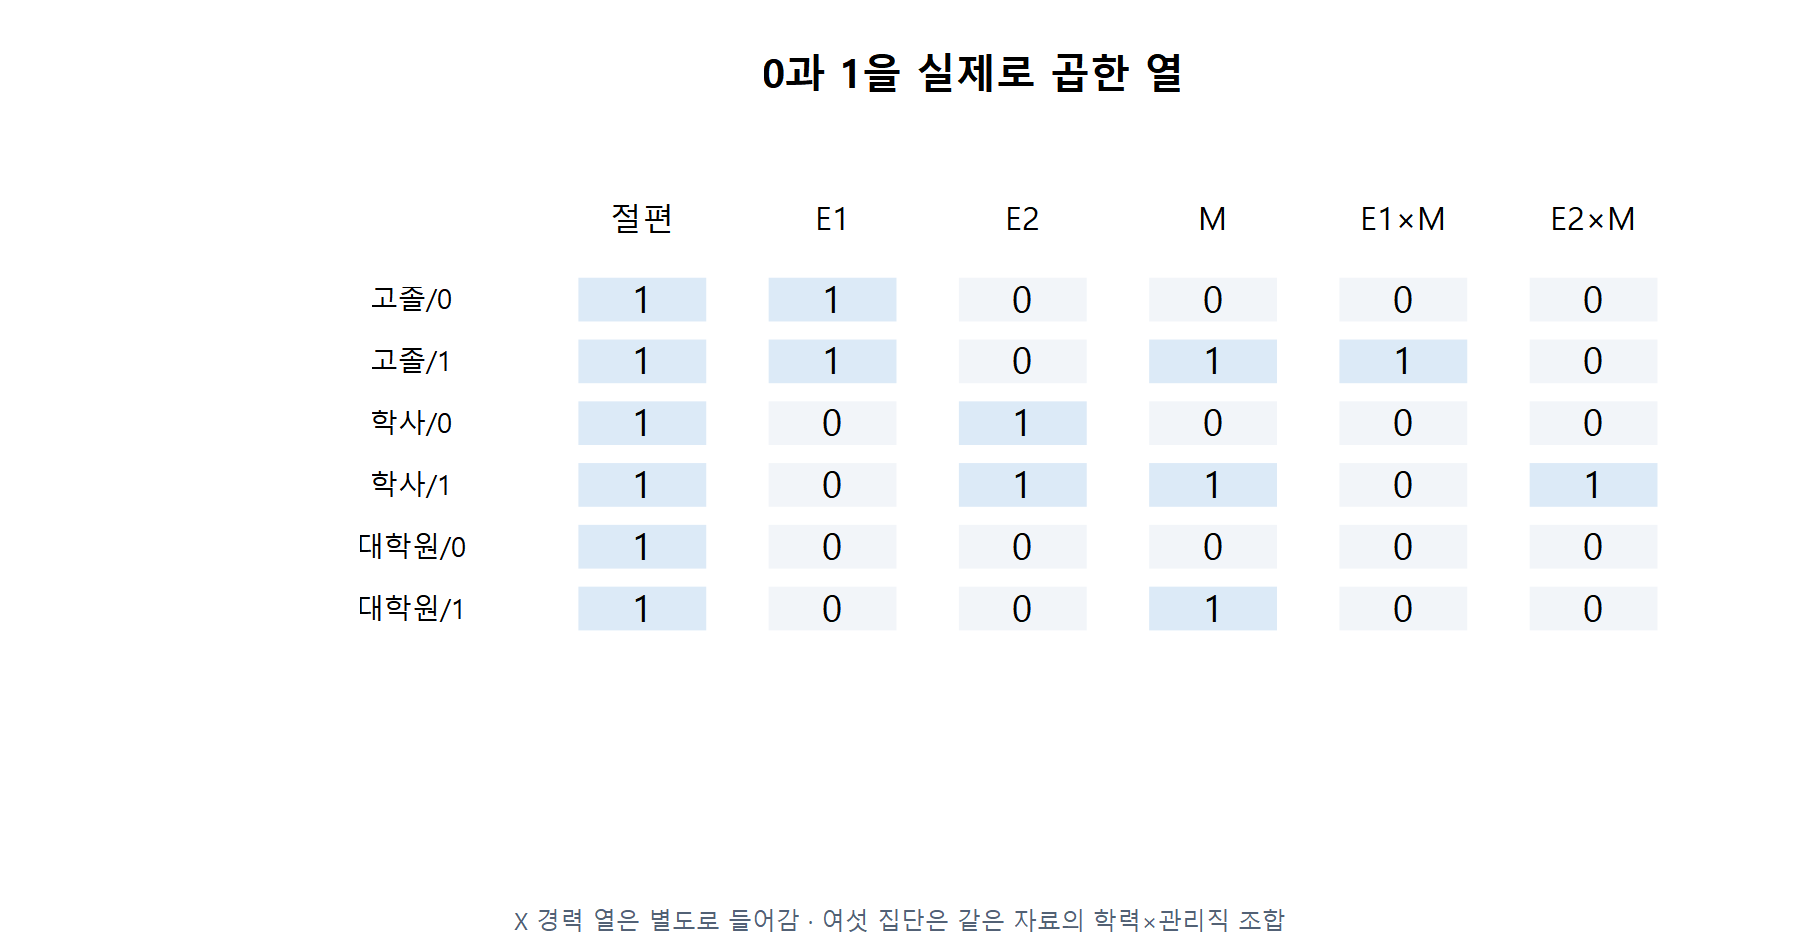

In [ ]:
salary_prepare <- function(data, reference=3L) {
  columns <- c("S","X","E","M")
  if (!is.data.frame(data) || !all(columns %in% names(data)) || nrow(data)<8L ||
      !all(vapply(data[columns],is.numeric,logical(1))) ||
      any(!is.finite(as.matrix(data[columns]))) ||
      any(!data$E %in% 1:3) || any(!data$M %in% 0:1))
    stop("Use complete finite S/X/E/M data; E=1,2,3 and M=0,1.")
  if (length(reference)!=1L || !is.numeric(reference) || !is.finite(reference) ||
      !reference %in% 1:3) stop("reference must be education code 1, 2 or 3.")
  labels <- c("HighSchool","Bachelor","Graduate")
  d <- data[columns]
  d$row_id <- seq_len(nrow(d))
  d$Education <- factor(labels[d$E],levels=c(labels[reference],labels[-reference]))
  contrasts(d$Education) <- contr.treatment(levels(d$Education),base=1)
  d
}
d <- salary_prepare(salary)
print(d[1:6,c("row_id","E","M","Education")])
print(model.matrix(sa)[1:6,])

## E02 · 한 사람의 항별 기여를 추적

함수의 첫 줄은 입력 모형을 검사합니다. model.matrix는 새 사람의 실제 열, sweep은 각 열×계수입니다. 결과는 행·항·값·계수·기여분이며 같은 row의 기여분 합이 평균 예측입니다.

![단계 그림](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f05.png)

[Figure source](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f05.png)

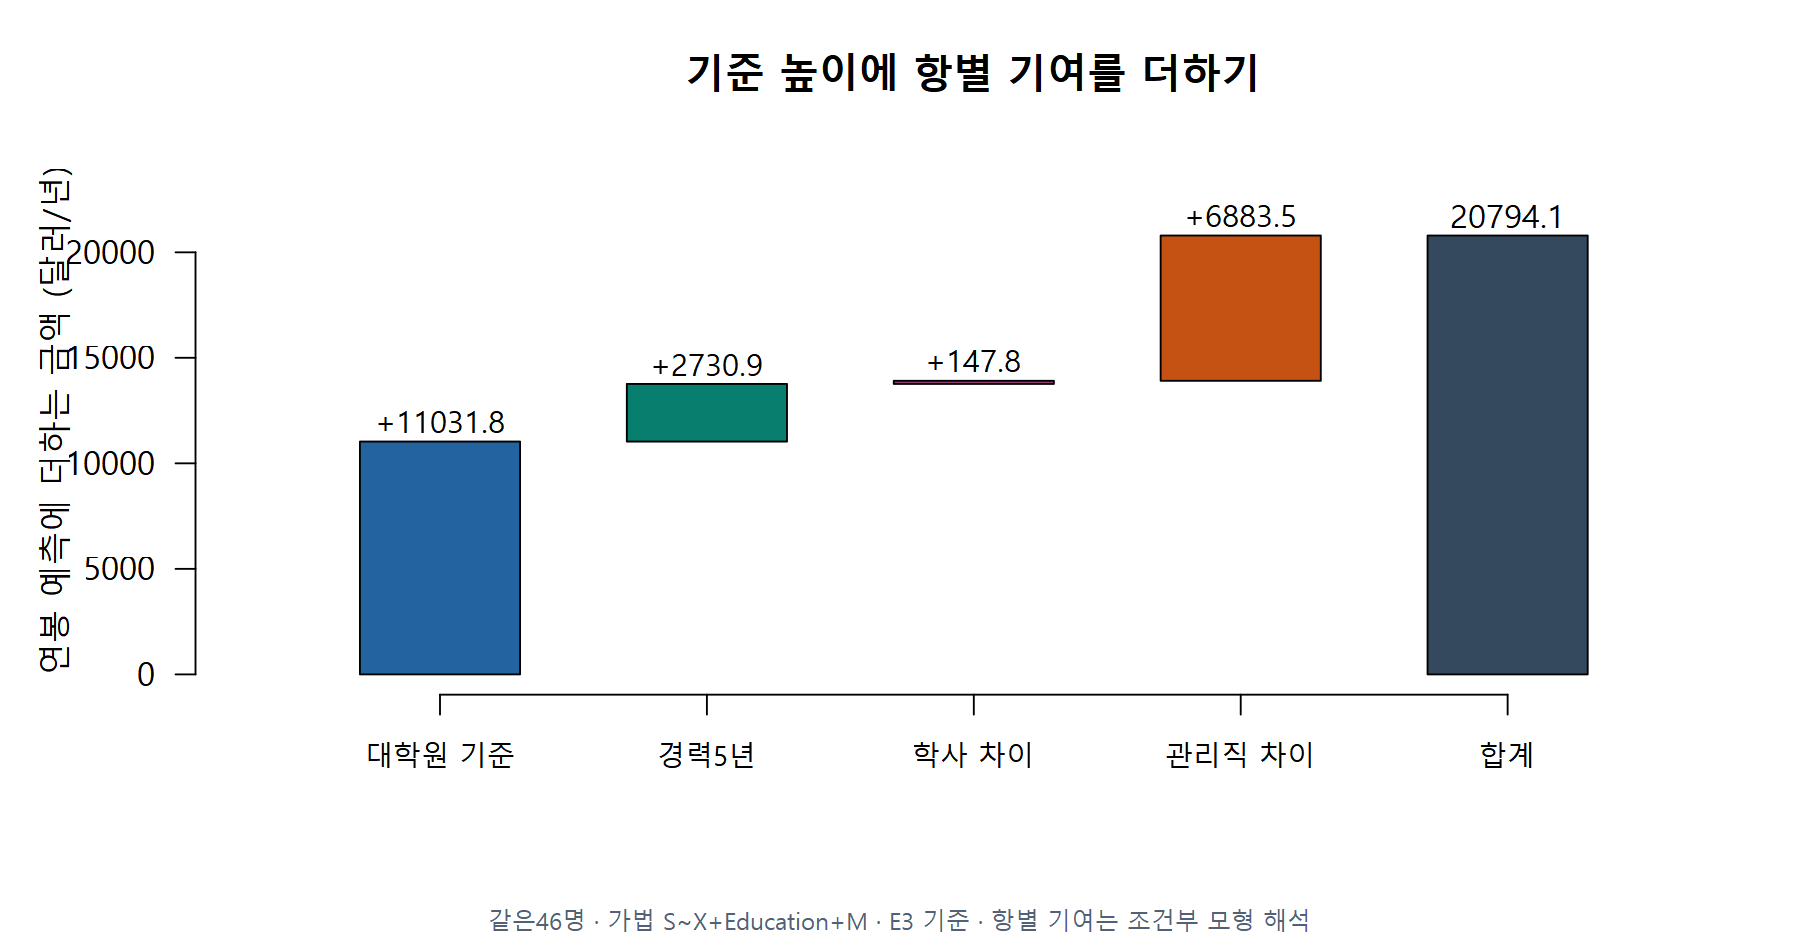

In [ ]:
cat_row_trace <- function(fit, newdata) {
  cat_check_fit(fit)
  if (!is.data.frame(newdata) || nrow(newdata)<1L)
    stop("newdata must contain at least one complete observation.")
  term <- delete.response(terms(fit))
  frame <- model.frame(term,newdata,na.action=na.fail,xlev=fit$xlevels)
  design <- model.matrix(term,frame,contrasts.arg=fit$contrasts)
  beta <- coef(fit)
  if (!identical(colnames(design),names(beta)) || any(!is.finite(design)))
    stop("New rows must use the fitted columns, factor levels and finite values.")
  contribution <- sweep(design,2,beta,"*")
  data.frame(row=rep(seq_len(nrow(design)),each=ncol(design)),
    term=rep(colnames(design),times=nrow(design)),
    value=as.vector(t(design)),coefficient=rep(unname(beta),times=nrow(design)),
    contribution=as.vector(t(contribution)),row.names=NULL)
}
one <- data.frame(X=5,Education=factor("Bachelor",levels=sa$xlevels$Education),M=1)
additive_row <- cat_row_trace(sa,one)
print(additive_row,digits=6)
print(c(sum_of_terms=sum(additive_row$contribution),predict=unname(predict(sa,one))))
barplot(additive_row$contribution,names.arg=additive_row$term,las=2,cex.names=.6,ylab="Contribution (USD/year)")

## E03 · 어떤 항을 추가해 다시 적합하는가

salary_fit의 실제 정의에서 S~X+Education*M을 찾으세요. X와 곱한 항은 없습니다. 전체46명과 명시적으로 제외한45명을 구분하는 검사도 함께 읽습니다.

![단계 그림](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f07.png)

[Figure source](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f07.png)

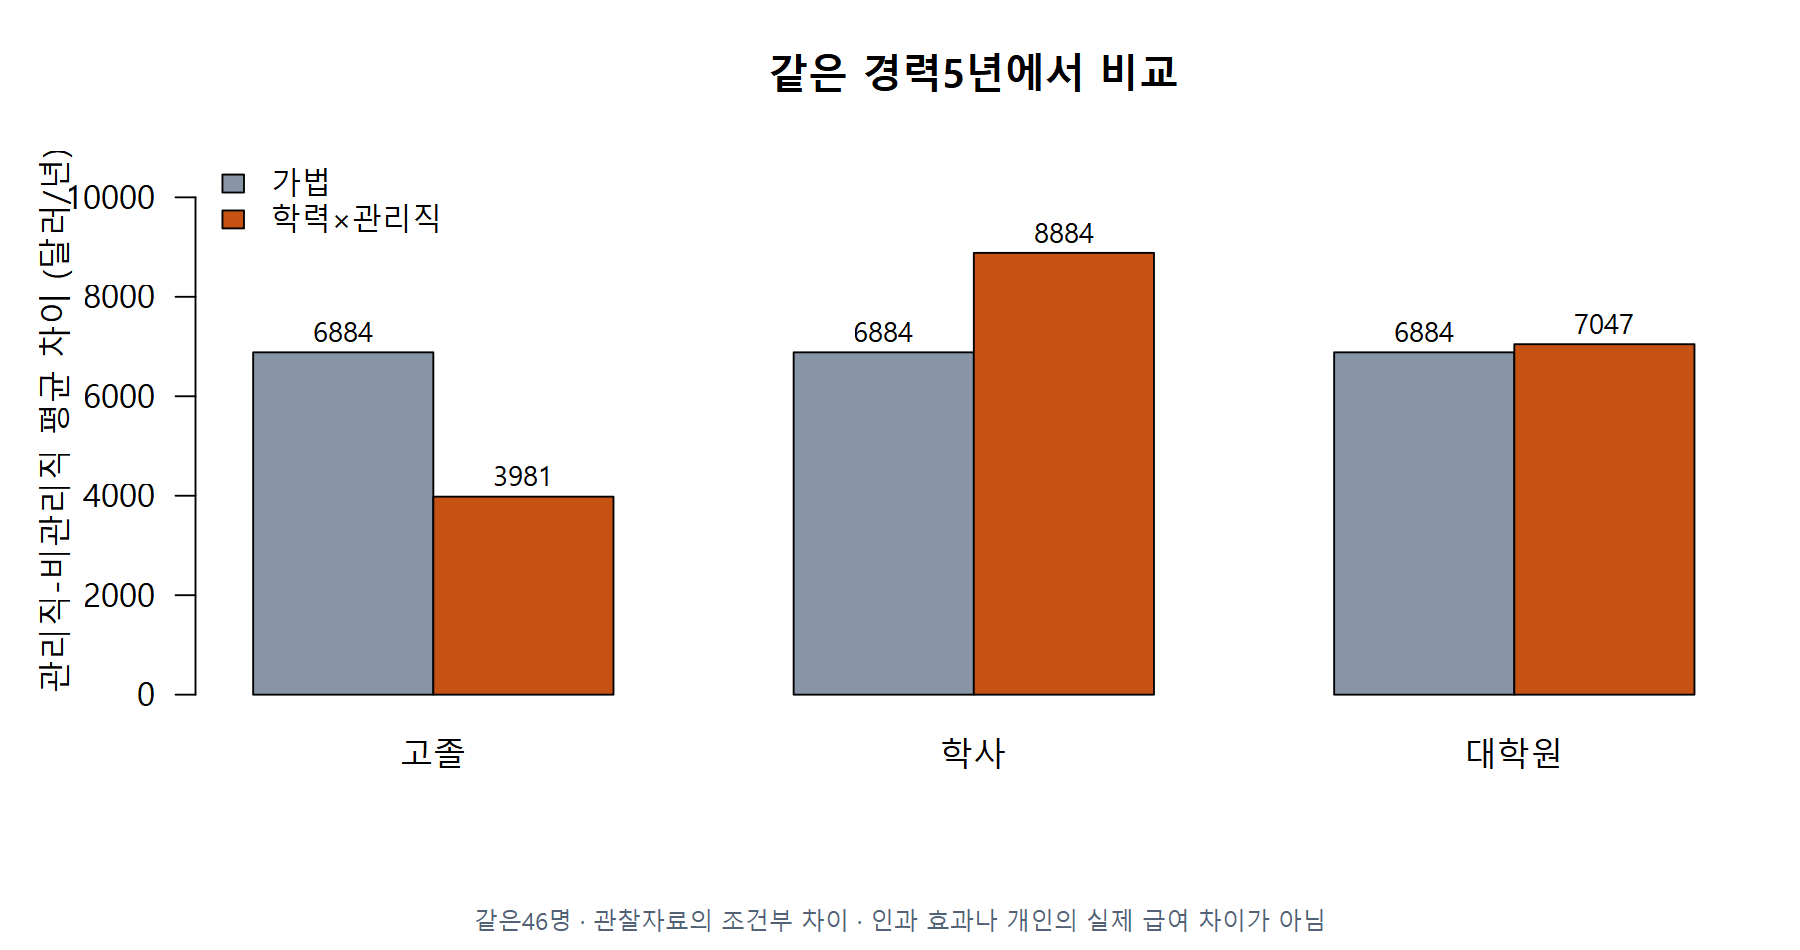

In [ ]:
salary_fit <- function(data, interaction=FALSE, omit_row=integer(), reference=3L) {
  if (length(interaction)!=1L || !is.logical(interaction) || is.na(interaction))
    stop("interaction must be TRUE or FALSE.")
  d <- salary_prepare(data,reference)
  if (!is.numeric(omit_row) || any(!is.finite(omit_row)) ||
      any(omit_row!=as.integer(omit_row)) || any(!omit_row %in% d$row_id))
    stop("omit_row must contain valid original row IDs, or integer().")
  selected <- d[!d$row_id %in% omit_row,,drop=FALSE]
  groups <- table(selected$Education,factor(selected$M,levels=0:1))
  if (any(groups==0L))
    stop("Keep observations in all six education/management groups for this teaching comparison.")
  formula <- if (interaction) S~X+Education*M else S~X+Education+M
  fit <- lm(formula,data=selected)
  if (fit$rank!=ncol(model.matrix(fit)) || df.residual(fit)<1L)
    stop("Selected rows do not support a full-rank model with residual degrees of freedom.")
  attr(fit,"salary_rows") <- selected$row_id
  attr(fit,"salary_interaction") <- interaction
  fit
}
full_row <- cat_row_trace(si,one)
print(full_row,digits=6)
print(salary_group_gaps(si,5),digits=6)
print(c(additive=sigma(sa),interaction=sigma(si)))

## 실제 최소제곱 계산을 안쪽에서 보기

lm이 사용하는 QR 방식과 연결합니다. design의 열, QR계수, 예측, 관측−예측, 제곱, 누적합을 순서대로 읽으세요. 이것은 명시적인 역행렬 계산이 아닙니다.

![단계 그림](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f09.png)

[Figure source](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f09.png)

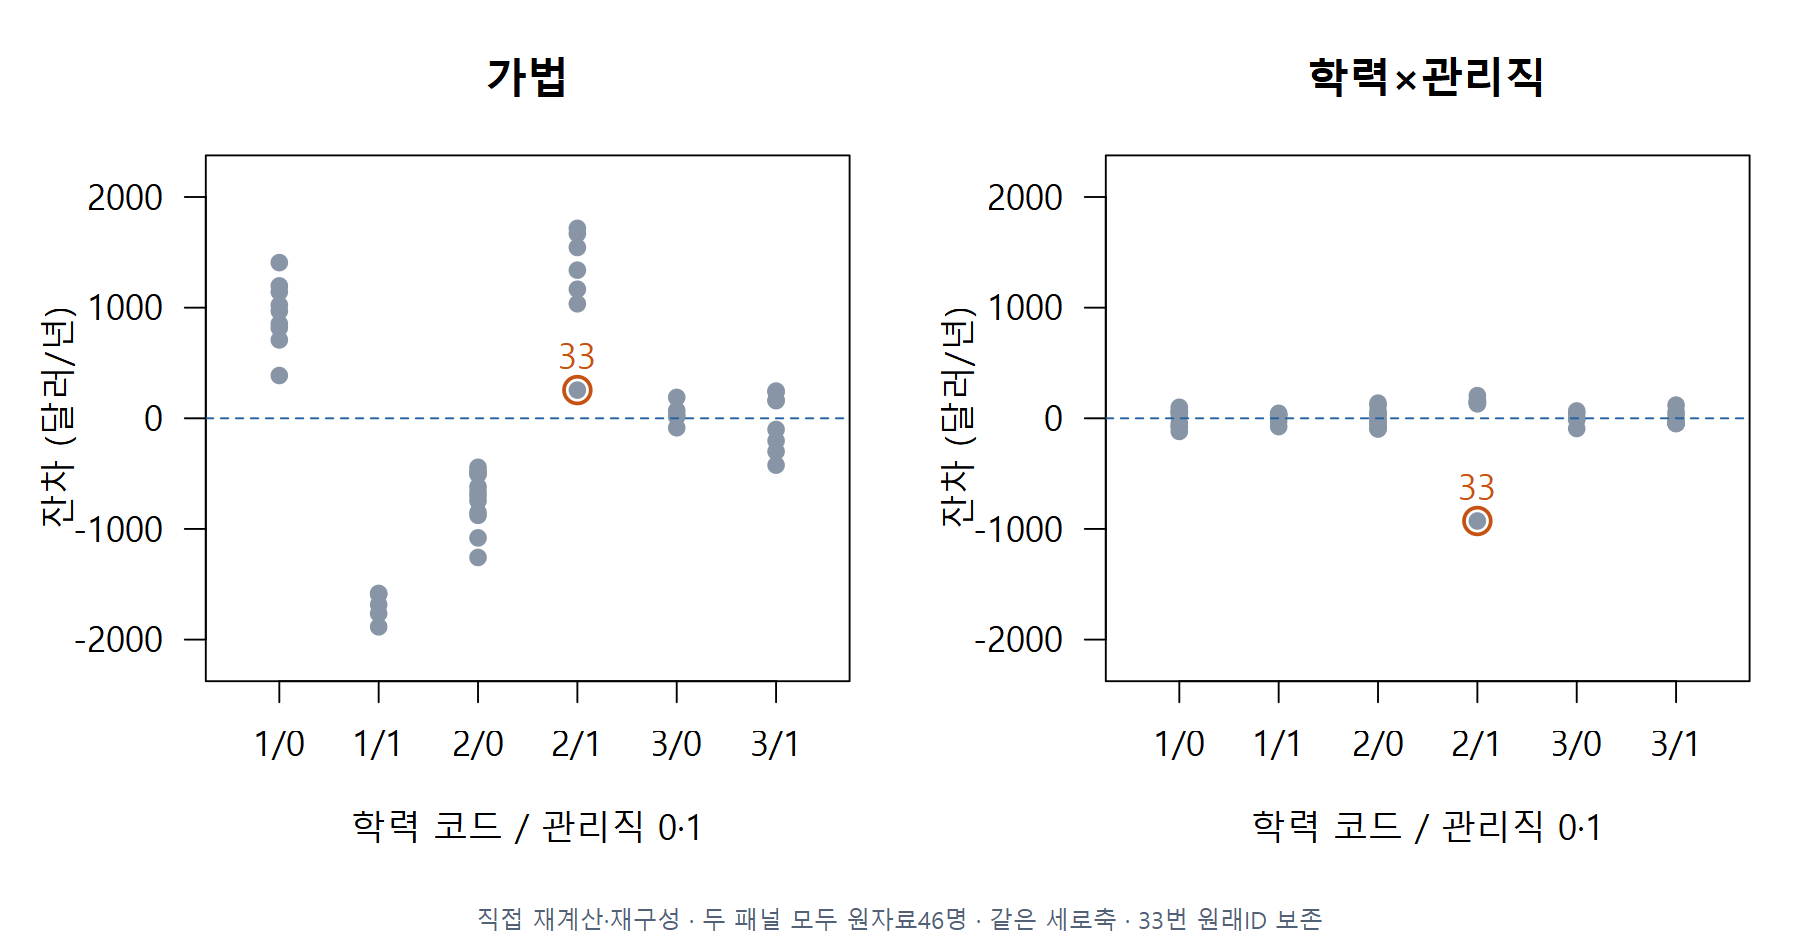

In [ ]:
cat_fit_trace <- function(fit) {
  frame <- cat_check_fit(fit)
  design <- model.matrix(fit)
  observed <- model.response(frame)
  beta <- qr.coef(qr(design),observed)
  fitted <- drop(design %*% beta)
  residual <- observed-fitted
  squared <- residual^2
  rows <- data.frame(source_row=rownames(design),observed=unname(observed),
    fitted=unname(fitted),residual=unname(residual),squared=unname(squared),
    cumulative=cumsum(unname(squared)),row.names=NULL)
  list(design=design,coefficients=beta,rows=rows,
    SSE=sum(squared),n=nrow(design),k=ncol(design),df=df.residual(fit))
}
salary_trace <- cat_fit_trace(si)
print(salary_trace$design[1:6,])
print(salary_trace$coefficients)
print(salary_trace$rows[1:6,],digits=6)
print(c(SSE=salary_trace$SSE,df=salary_trace$df,sigma=sqrt(salary_trace$SSE/salary_trace$df)))

## E04 · 기준 변경과 원자료 보존 민감도

기준만 바꾼 모형의 적합값과 33번을 제외한 별도 분석을 구별합니다. 실제 원자료46명은 그대로 둡니다. X=0 및 집단별 관측 범위 밖은 외삽입니다.

![단계 그림](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f10.png)

[Figure source](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11a-v2/course/notion/w11a/images/w11a-f10.png)

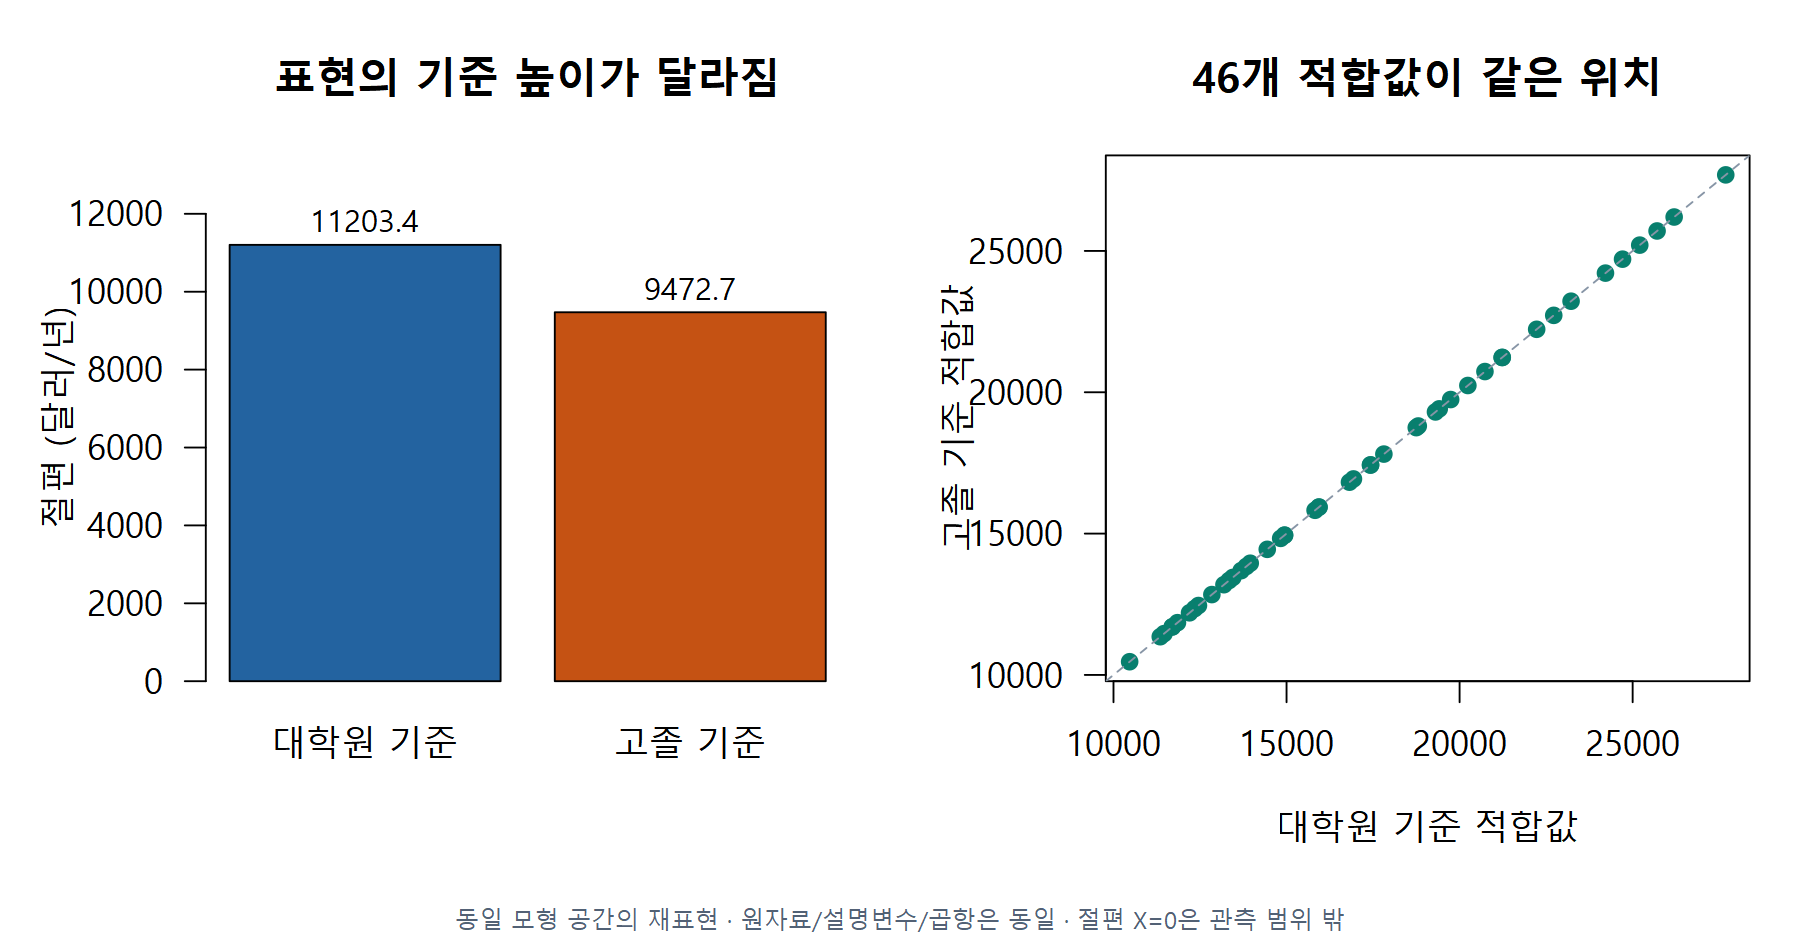

In [ ]:
reference1 <- salary_fit(salary,TRUE,reference=1)
print(coef(si));print(coef(reference1))
print(max(abs(fitted(si)-fitted(reference1))))
sensitivity <- salary_fit(salary,TRUE,omit_row=33)
print(data.frame(model=c("all46","separate45"),n=c(nobs(si),nobs(sensitivity)),sigma=c(sigma(si),sigma(sensitivity))))
print(aggregate(X~E+M,salary,range))

### L01 · 한 사람의 0/1 행

목표: 기준범주와 곱항

고졸·비관리직·경력 4년인 사람의 절편/E1/E2/M/E1M/E2M을 순서대로 쓰세요. 기준은 대학원입니다. 대학원 사람이 자료에서 삭제됐는지도 설명하세요.

힌트: 조건에 맞는 열만 1입니다. 절편 열은 모든 행에서 1입니다.

자가 점검: 실행 전에 0/1 행과 이유를 적고 model.matrix의 같은 조건과 비교합니다.

In [ ]:
my_L01_prediction <- NA_real_
my_L01_reason <- ""
# Record a prediction first; an unfinished answer does not block the examples.

### L02 · 예측의 각 항 더하기

목표: 수식에서 한 사람의 평균 예측

E02의 가법 계수로 고졸·관리직·경력 4년의 평균 연봉을 손으로 구하세요. 경력만 5년으로 바꾸면 얼마나 변하나요? 기준만 고졸로 바꾸면 같은 사람의 예측이 변할까요?

힌트: 학사는 0, 고졸과 관리직은 1입니다. 반올림 차이는 기록합니다.

자가 점검: 기여분 표의 합과 predict가 일치하는지 확인합니다.

In [ ]:
my_L02_prediction <- NA_real_
my_L02_reason <- ""
# Record a prediction first; an unfinished answer does not block the examples.

### L03 · 관리직 격차와 공통 기울기

목표: 범주×범주 상호작용

전체 46명 상호작용 모형에서 고졸의 관리직 격차를 구하고 학사와 비교하세요. 경력을 4년에서 6년으로 바꾸면 각 집단의 연봉 증가량과 관리직 격차는 어떻게 되나요?

힌트: 관리직 주효과에 해당 학력의 곱항을 더합니다. X와 곱한 항이 있는지도 봅니다.

자가 점검: 여섯 집단의 예측에서 같은 학력의 두 평균을 뺀 값과 비교합니다.

In [ ]:
my_L03_prediction <- NA_real_
my_L03_reason <- ""
# Record a prediction first; an unfinished answer does not block the examples.

### L07 · 겹치는 열 찾기

목표: 더미 함정

절편과 E1/E2/E3을 모두 둔 식에서 절편에 100을 더하고 모든 학력 계수에서 100을 빼면 예측은 어떻게 되나요? 왜 계수가 하나로 정해지지 않나요?

힌트: 한 사람에게서 세 학력 더미의 합은 1입니다.

자가 점검: 고졸·학사·대학원을 각각 대입해 봅니다.

In [ ]:
my_L07_prediction <- NA_real_
my_L07_reason <- ""
# Record a prediction first; an unfinished answer does not block the examples.

### L08 · 같은 사람끼리 비교하는가

목표: 비교 가능한 자료와 외삽

M0는 20명, MF는 결측값 때문에 19명으로 적합했습니다. 두 SSE를 바로 부분 F에 넣어도 될까요? 급료조사 전체에 경력 20년이 있으면 모든 학력·관리직의 20년 예측이 관측 범위 안인지도 설명하세요.

힌트: 오차 감소가 모형 변화인지 자료 변화인지 구별해야 합니다. 집단별 X 범위도 확인합니다.

자가 점검: 모형 행의 ID와 반응값, 집단별 경력 범위를 기록합니다.

In [ ]:
my_L08_prediction <- NA_real_
my_L08_reason <- ""
# Record a prediction first; an unfinished answer does not block the examples.

## 입력 검사 부록

같은 행·반응값·중첩·완전계수 조건을 검사하는 실제 정의입니다. 별도 API 페이지를 열지 않고도 읽을 수 있습니다.

In [ ]:
cat_check_fit <- function(fit) {
  if (!inherits(fit,"lm") || !is.data.frame(fit$model))
    stop("Use a standard lm with its complete model frame retained.")
  frame <- fit$model
  design <- model.matrix(fit)
  y <- model.response(frame)
  if (!is.numeric(y) || is.matrix(y) || any(!is.finite(y)) ||
      any(!is.finite(design)) || !is.null(model.weights(frame)) ||
      !is.null(model.offset(frame)) || fit$rank!=ncol(design) ||
      df.residual(fit)<1L || any(!is.finite(coef(fit))))
    stop("Require finite, unweighted, no-offset, full-rank univariate OLS with residual df.")
  frame
}

In [ ]:
cat_check_pair <- function(reduced, full, tolerance=1e-9) {
  r <- cat_check_fit(reduced)
  f <- cat_check_fit(full)
  if (!identical(rownames(r),rownames(f)) ||
      !isTRUE(all.equal(model.response(r),model.response(f),tolerance=0)))
    stop("Compare the same response and identical observations in identical order.")
  xr <- model.matrix(reduced)
  xf <- model.matrix(full)
  if (length(tolerance)!=1L || !is.numeric(tolerance) ||
      !is.finite(tolerance) || tolerance<=0) stop("Use positive finite tolerance.")
  q <- full$rank-reduced$rank
  if (q<=0 || max(abs(qr.resid(qr(xf),xr)))>tolerance*max(1,abs(xr)))
    stop("Reduced design must be nested in full design with fewer parameters.")
  list(n=nrow(f),q=q,df_full=df.residual(full))
}

In [ ]:
stopifnot(nrow(salary)==46,nrow(pre)==20,si$rank==7,df.residual(si)==39,
 max(abs(salary_trace$rows$fitted-fitted(si)))<1e-7,
 abs(sum(additive_row$contribution)-predict(sa,one))<1e-7,
 max(abs(fitted(si)-fitted(reference1)))<1e-7)
cat("W11A_CATEGORICAL_RUNTIME_PASS: source calculations, not exercise completion\n")